In [8]:
pwd

'G:\\IoT_IDS_Research'

In [1]:
import os
os.chdir(r'G:\IoT_IDS_Research')

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import time

In [11]:
pwd

'G:\\IoT_IDS_Research'

In [12]:
# IoT IDS Preprocessing Pipeline for CIC IoT Attack Dataset 2023
# Author: Prepared for IoT Security IDS research
# Purpose: Clean, optimize, sample, and prepare merged CICIoT2023 CSV files for ML experiments.

from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

# =========================
# 1. CONFIGURATION
# =========================

RAW_DIR = Path("data/raw")              # Put your 63 merged CSV files here
PROCESSED_DIR = Path("data/processed")  # Cleaned files will be saved here
OUTPUT_DIR = Path("outputs")            # Reports/encoders/scalers

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COL = "Label"
CHUNK_SIZE = 100_000

# For your laptop, start with a small sample.
# Later you can increase this to 500000 or 1000000.
FINAL_SAMPLE_SIZE = 200_000

# Balanced binary sampling settings.
# For FINAL_SAMPLE_SIZE = 200_000, the script will try to create:
#   100,000 BENIGN rows + 100,000 ATTACK rows.
# If one class has fewer rows in the cleaned dataset, the script will use the
# maximum possible balanced size without duplicating rows.
BALANCED_BINARY_SAMPLE = True
ALLOW_REPLACEMENT_IF_MINORITY_SHORT = False

RANDOM_STATE = 42

In [13]:
# =========================
# 2. ATTACK CATEGORY MAPPING
# =========================

def map_attack_category(label: str) -> str:
    """
    Map 34 fine-grained CICIoT2023 labels into broader attack categories.
    This is useful for multiclass category-level IDS.
    """
    label = str(label).upper().strip()

    if label == "BENIGN":
        return "BENIGN"
    elif label.startswith("DDOS"):
        return "DDOS"
    elif label.startswith("DOS"):
        return "DOS"
    elif label.startswith("MIRAI"):
        return "MIRAI"
    elif label.startswith("RECON"):
        return "RECON"
    elif "SPOOFING" in label or "MITM" in label:
        return "SPOOFING"
    elif label in ["SQLINJECTION", "COMMANDINJECTION", "XSS", "BROWSERHIJACKING", "UPLOADING_ATTACK", "BACKDOOR_MALWARE"]:
        return "WEB_OR_MALWARE"
    elif label == "DICTIONARYBRUTEFORCE":
        return "BRUTEFORCE"
    elif label == "VULNERABILITYSCAN":
        return "VULNERABILITY_SCAN"
    else:
        return "OTHER"

In [14]:
# =========================
# 3. MEMORY OPTIMIZATION
# =========================

def optimize_dtypes(df: pd.DataFrame) -> pd.DataFrame:
    """
    Reduce RAM usage by converting float64 to float32 and int64 to smaller integer types.
    """
    for col in df.select_dtypes(include=["float64"]).columns:
        df[col] = df[col].astype("float32")

    for col in df.select_dtypes(include=["int64"]).columns:
        df[col] = pd.to_numeric(df[col], downcast="integer")

    return df

In [15]:
# =========================
# 4. CLEAN ONE CHUNK
# =========================

def clean_chunk(chunk: pd.DataFrame) -> pd.DataFrame:
    """
    Clean one chunk of the dataset.
    """
    # Remove spaces from column names for easier coding
    chunk.columns = [c.strip().replace(" ", "_") for c in chunk.columns]

    target_col = TARGET_COL
    if TARGET_COL not in chunk.columns and "Label" in chunk.columns:
        target_col = "Label"

    # Replace infinity with NaN
    chunk = chunk.replace([np.inf, -np.inf], np.nan)

    # Fill numeric missing values with median of the chunk
    numeric_cols = chunk.select_dtypes(include=[np.number]).columns
    for col in numeric_cols:
        if chunk[col].isna().any():
            chunk[col] = chunk[col].fillna(chunk[col].median())

    # Drop rows without label
    if target_col in chunk.columns:
        chunk[target_col] = chunk[target_col].astype(str).str.upper().str.strip()
        chunk = chunk[chunk[target_col] != ""]
        chunk = chunk.dropna(subset=[target_col])

        # Create binary and category labels
        chunk["Binary_Label"] = chunk[target_col].apply(lambda x: 0 if x == "BENIGN" else 1)
        chunk["Attack_Category"] = chunk[target_col].apply(map_attack_category)

    # Remove duplicate rows inside the chunk
    chunk = chunk.drop_duplicates()

    # Optimize RAM
    chunk = optimize_dtypes(chunk)

    return chunk

In [16]:
# =========================
# 5. PREPROCESS ALL CSV FILES
# =========================

def preprocess_all_files():
    csv_files = sorted(RAW_DIR.glob("*.csv"))

    if not csv_files:
        raise FileNotFoundError(f"No CSV files found in {RAW_DIR.resolve()}")

    print(f"Found {len(csv_files)} CSV files.")

    processed_files = []

    for file_index, csv_file in enumerate(csv_files, start=1):
        print(f"\nProcessing file {file_index}/{len(csv_files)}: {csv_file.name}")

        output_file = PROCESSED_DIR / f"cleaned_{csv_file.stem}.parquet"

        cleaned_chunks = []
        total_rows = 0

        for chunk in pd.read_csv(csv_file, chunksize=CHUNK_SIZE):
            total_rows += len(chunk)
            cleaned = clean_chunk(chunk)
            cleaned_chunks.append(cleaned)

        file_df = pd.concat(cleaned_chunks, ignore_index=True)
        file_df = file_df.drop_duplicates()

        file_df.to_parquet(output_file, index=False)
        processed_files.append(output_file)

        print(f"Original rows read: {total_rows}")
        print(f"Cleaned rows saved: {len(file_df)}")
        print(f"Saved: {output_file}")

    return processed_files

In [17]:
# =========================
# 6. CREATE FINAL BALANCED SAMPLE
# =========================

def _allocate_samples(counts, target):
    """
    Allocate a target number of samples across files proportionally to the
    available class counts in each file.

    This avoids selecting too many rows from a file that has very few BENIGN
    or ATTACK samples.
    """
    counts = np.array(counts, dtype=np.int64)
    total_available = int(counts.sum())

    if total_available == 0 or target <= 0:
        return [0] * len(counts)

    target = min(int(target), total_available)

    raw_alloc = (counts / total_available) * target
    alloc = np.floor(raw_alloc).astype(np.int64)

    # Never allocate more than available in any file.
    alloc = np.minimum(alloc, counts)

    # Distribute the remaining samples to files that still have capacity.
    remaining = target - int(alloc.sum())
    fractional_order = np.argsort(-(raw_alloc - np.floor(raw_alloc)))

    while remaining > 0:
        changed = False
        for idx in fractional_order:
            if remaining == 0:
                break
            if alloc[idx] < counts[idx]:
                alloc[idx] += 1
                remaining -= 1
                changed = True
        if not changed:
            break

    return alloc.tolist()


def create_final_sample(processed_files):
    """
    Create one balanced binary working sample from all cleaned parquet files.

    This is better than ordinary random sampling for IDS research because the
    raw CICIoT2023 distribution is highly imbalanced. The default setting tries
    to create 50% BENIGN and 50% ATTACK samples.
    """
    print("\nCreating final balanced research sample...")

    if not BALANCED_BINARY_SAMPLE:
        print("BALANCED_BINARY_SAMPLE=False, using ordinary random sampling.")
        sample_parts = []
        per_file_sample = max(1000, FINAL_SAMPLE_SIZE // len(processed_files))

        for file in processed_files:
            df = pd.read_parquet(file)
            if len(df) > per_file_sample:
                df_sample = df.sample(n=per_file_sample, random_state=RANDOM_STATE)
            else:
                df_sample = df
            sample_parts.append(df_sample)

        sample_df = pd.concat(sample_parts, ignore_index=True)
        if len(sample_df) > FINAL_SAMPLE_SIZE:
            sample_df = sample_df.sample(n=FINAL_SAMPLE_SIZE, random_state=RANDOM_STATE)

    else:
        # First pass: count class availability in every cleaned file.
        file_stats = []
        total_benign = 0
        total_attack = 0

        for file in processed_files:
            df = pd.read_parquet(file, columns=["Binary_Label"])
            benign_count = int((df["Binary_Label"] == 0).sum())
            attack_count = int((df["Binary_Label"] == 1).sum())
            file_stats.append({
                "file": file,
                "benign": benign_count,
                "attack": attack_count
            })
            total_benign += benign_count
            total_attack += attack_count

        desired_per_class = FINAL_SAMPLE_SIZE // 2

        if ALLOW_REPLACEMENT_IF_MINORITY_SHORT:
            benign_target = desired_per_class
            attack_target = desired_per_class
        else:
            # Without replacement, a truly balanced sample cannot exceed the
            # available minority class size.
            per_class_possible = min(desired_per_class, total_benign, total_attack)
            benign_target = per_class_possible
            attack_target = per_class_possible

            if per_class_possible < desired_per_class:
                print("WARNING: Not enough rows in one class for the requested balanced sample.")
                print(f"Requested per class: {desired_per_class}")
                print(f"Available BENIGN   : {total_benign}")
                print(f"Available ATTACK   : {total_attack}")
                print(f"Using per class    : {per_class_possible}")

        print("\nAvailable cleaned rows:")
        print(f"BENIGN: {total_benign}")
        print(f"ATTACK: {total_attack}")
        print("\nSampling target:")
        print(f"BENIGN: {benign_target}")
        print(f"ATTACK: {attack_target}")

        benign_alloc = _allocate_samples(
            [s["benign"] for s in file_stats],
            benign_target
        )
        attack_alloc = _allocate_samples(
            [s["attack"] for s in file_stats],
            attack_target
        )

        sample_parts = []

        for idx, stat in enumerate(file_stats):
            file = stat["file"]
            n_benign = benign_alloc[idx]
            n_attack = attack_alloc[idx]

            if n_benign == 0 and n_attack == 0:
                continue

            df = pd.read_parquet(file)
            parts = []

            benign_df = df[df["Binary_Label"] == 0]
            attack_df = df[df["Binary_Label"] == 1]

            if n_benign > 0:
                replace_b = ALLOW_REPLACEMENT_IF_MINORITY_SHORT and len(benign_df) < n_benign
                parts.append(benign_df.sample(
                    n=n_benign,
                    replace=replace_b,
                    random_state=RANDOM_STATE + idx
                ))

            if n_attack > 0:
                replace_a = ALLOW_REPLACEMENT_IF_MINORITY_SHORT and len(attack_df) < n_attack
                parts.append(attack_df.sample(
                    n=n_attack,
                    replace=replace_a,
                    random_state=RANDOM_STATE + idx
                ))

            file_sample = pd.concat(parts, ignore_index=True)
            sample_parts.append(file_sample)

            print(
                f"Sampled from {file.name}: "
                f"BENIGN={n_benign}, ATTACK={n_attack}"
            )

        sample_df = pd.concat(sample_parts, ignore_index=True)

    # Shuffle final sample.
    sample_df = sample_df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

    output_sample = PROCESSED_DIR / f"balanced_final_sample_{len(sample_df)}.csv"
    compatibility_sample = PROCESSED_DIR / f"final_sample_{FINAL_SAMPLE_SIZE}.csv"

    sample_df.to_csv(output_sample, index=False)
    sample_df.to_csv(compatibility_sample, index=False)

    print(f"\nFinal sample shape: {sample_df.shape}")
    print("Binary label distribution:")
    print(sample_df["Binary_Label"].value_counts().sort_index())
    print(f"Saved balanced sample: {output_sample}")
    print(f"Saved compatibility copy: {compatibility_sample}")

    return sample_df, output_sample

In [18]:
# =========================
# 7. CREATE TRAIN-TEST DATA
# =========================

def create_train_test(sample_df: pd.DataFrame):
    """
    Prepare X_train, X_test, y_train, y_test for Binary IDS.
    """
    df = sample_df.copy()

    # Ensure column names are safe
    df.columns = [c.strip().replace(" ", "_") for c in df.columns]

    # Columns not used as features
    drop_cols = ["Label", "Binary_Label", "Attack_Category"]

    feature_cols = [c for c in df.columns if c not in drop_cols]

    X = df[feature_cols]
    y = df["Binary_Label"]

    # Train-test split with stratification
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y
    )

    # Scale features for models that need scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Save outputs
    pd.DataFrame(X_train_scaled, columns=feature_cols).to_csv(PROCESSED_DIR / "X_train_scaled.csv", index=False)
    pd.DataFrame(X_test_scaled, columns=feature_cols).to_csv(PROCESSED_DIR / "X_test_scaled.csv", index=False)
    y_train.to_csv(PROCESSED_DIR / "y_train_binary.csv", index=False)
    y_test.to_csv(PROCESSED_DIR / "y_test_binary.csv", index=False)

    joblib.dump(scaler, OUTPUT_DIR / "standard_scaler.joblib")

    print("\nTrain-test files saved.")
    print("X_train:", X_train.shape)
    print("X_test :", X_test.shape)

    return X_train, X_test, y_train, y_test


In [19]:
# =========================
# 8. DATASET REPORT
# =========================

def save_dataset_report(sample_df: pd.DataFrame):
    report_path = OUTPUT_DIR / "dataset_preprocessing_report.txt"

    with open(report_path, "w", encoding="utf-8") as f:
        f.write("CICIoT2023 Preprocessing Report\n")
        f.write("================================\n\n")
        f.write(f"Final sample shape: {sample_df.shape}\n\n")

        f.write("Columns:\n")
        for col in sample_df.columns:
            f.write(f"- {col}\n")

        f.write("\nFine-grained label distribution:\n")
        f.write(sample_df["Label"].value_counts().to_string())

        f.write("\n\nBinary label distribution:\n")
        f.write(sample_df["Binary_Label"].value_counts().to_string())

        f.write("\n\nAttack category distribution:\n")
        f.write(sample_df["Attack_Category"].value_counts().to_string())

        f.write("\n\nMissing values:\n")
        f.write(sample_df.isna().sum().to_string())

    print(f"Dataset report saved: {report_path}")


In [20]:
# =========================
# 9. MAIN EXECUTION
# =========================

if __name__ == "__main__":
    processed_files = preprocess_all_files()
    sample_df, sample_file = create_final_sample(processed_files)
    save_dataset_report(sample_df)
    create_train_test(sample_df)

    print("\nPreprocessing completed successfully.")

Found 63 CSV files.

Processing file 1/63: Merged01.csv
Original rows read: 712311
Cleaned rows saved: 544719
Saved: data\processed\cleaned_Merged01.parquet

Processing file 2/63: Merged02.csv
Original rows read: 748585
Cleaned rows saved: 568413
Saved: data\processed\cleaned_Merged02.parquet

Processing file 3/63: Merged03.csv
Original rows read: 697289
Cleaned rows saved: 535043
Saved: data\processed\cleaned_Merged03.parquet

Processing file 4/63: Merged04.csv
Original rows read: 676620
Cleaned rows saved: 520986
Saved: data\processed\cleaned_Merged04.parquet

Processing file 5/63: Merged05.csv
Original rows read: 744804
Cleaned rows saved: 565931
Saved: data\processed\cleaned_Merged05.parquet

Processing file 6/63: Merged06.csv
Original rows read: 718229
Cleaned rows saved: 548654
Saved: data\processed\cleaned_Merged06.parquet

Processing file 7/63: Merged07.csv
Original rows read: 702212
Cleaned rows saved: 538212
Saved: data\processed\cleaned_Merged07.parquet

Processing file 8/63

In [12]:
X_train = pd.read_csv("data/processed/X_train_scaled.csv")
X_test = pd.read_csv("data/processed/X_test_scaled.csv")

y_train = pd.read_csv("data/processed/y_train_binary.csv").values.ravel()
y_test = pd.read_csv("data/processed/y_test_binary.csv").values.ravel()

print(X_train.shape)
print(X_test.shape)

(160000, 39)
(40000, 39)


In [13]:
start = time.time()

rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

end = time.time()

print("Training Time:", end - start, "seconds")

Training Time: 9.08340311050415 seconds


In [14]:
y_pred_rf = rf.predict(X_test)

In [15]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("F1 Score:", f1_score(y_test, y_pred_rf))

print(classification_report(y_test, y_pred_rf))

print(confusion_matrix(y_test, y_pred_rf))

Accuracy: 0.988625
F1 Score: 0.98850400464893
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     20000
           1       1.00      0.98      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[19983    17]
 [  438 19562]]


In [16]:
feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(20))

            Feature  Importance
37           Number    0.180405
8   ack_flag_number    0.123021
16            HTTPS    0.108894
35         Tot_size    0.079274
3              Rate    0.070434
0     Header_Length    0.070165
36              IAT    0.064648
33              AVG    0.061281
11        ack_count    0.052884
38         Variance    0.035861
34              Std    0.033769
32              Max    0.026490
30          Tot_sum    0.022303
2      Time_To_Live    0.020363
31              Min    0.011279
7   psh_flag_number    0.010376
22              TCP    0.007668
12        syn_count    0.004092
5   syn_flag_number    0.003482
1     Protocol_Type    0.002417


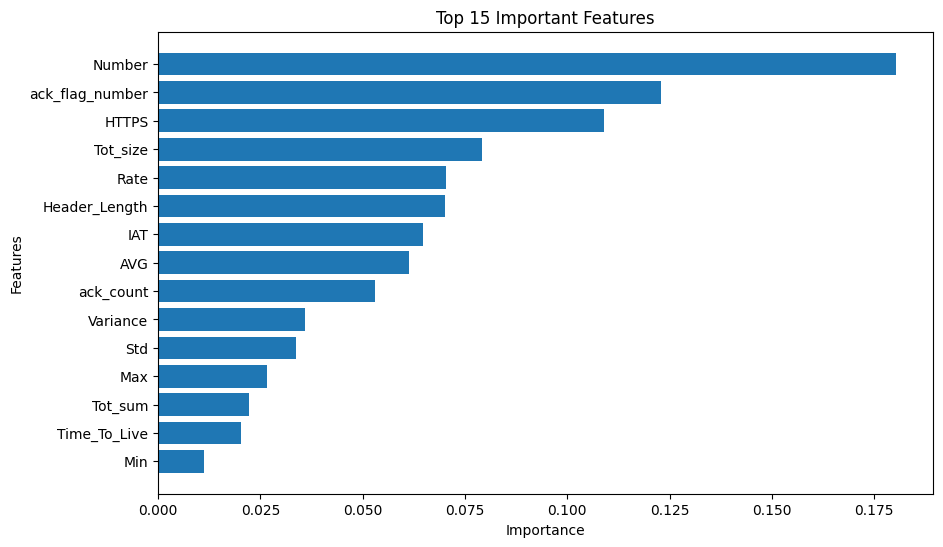

In [17]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Features")

plt.title("Top 15 Important Features")

plt.show()

In [18]:
#STEP 1 — Select Top Features
top_5 = feature_importance.head(5)['Feature'].tolist()

top_10 = feature_importance.head(10)['Feature'].tolist()

top_15 = feature_importance.head(15)['Feature'].tolist()

print(top_5)
print(top_10)
print(top_15)

['Number', 'ack_flag_number', 'HTTPS', 'Tot_size', 'Rate']
['Number', 'ack_flag_number', 'HTTPS', 'Tot_size', 'Rate', 'Header_Length', 'IAT', 'AVG', 'ack_count', 'Variance']
['Number', 'ack_flag_number', 'HTTPS', 'Tot_size', 'Rate', 'Header_Length', 'IAT', 'AVG', 'ack_count', 'Variance', 'Std', 'Max', 'Tot_sum', 'Time_To_Live', 'Min']


In [19]:
#Train Using ONLY Top 5 Features
X_train_5 = X_train[top_5]
X_test_5 = X_test[top_5]

In [20]:
#Train Model
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
import time

start = time.time()

rf_5 = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_5.fit(X_train_5, y_train)

end = time.time()

y_pred_5 = rf_5.predict(X_test_5)

print("Training Time:", end - start)

print("Accuracy:", accuracy_score(y_test, y_pred_5))

print("F1 Score:", f1_score(y_test, y_pred_5))

Training Time: 6.088242053985596
Accuracy: 0.984525
F1 Score: 0.9843223665881519


In [21]:
#Train Using ONLY Top 10 Features
X_train_10 = X_train[top_10]
X_test_10 = X_test[top_10]

In [22]:
start = time.time()

rf_10 = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_10.fit(X_train_10, y_train)

end = time.time()

y_pred_10 = rf_10.predict(X_test_10)

print("Training Time:", end - start)

print("Accuracy:", accuracy_score(y_test, y_pred_10))

print("F1 Score:", f1_score(y_test, y_pred_10))

Training Time: 9.987819194793701
Accuracy: 0.98555
F1 Score: 0.985362641815235


In [23]:
#Train Using ONLY Top 15 Features
X_train_15 = X_train[top_15]
X_test_15 = X_test[top_15]

In [24]:
start = time.time()

rf_15 = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_15.fit(X_train_15, y_train)

end = time.time()

y_pred_15 = rf_15.predict(X_test_15)

print("Training Time:", end - start)

print("Accuracy:", accuracy_score(y_test, y_pred_15))

print("F1 Score:", f1_score(y_test, y_pred_15))


Training Time: 9.85162091255188
Accuracy: 0.9885
F1 Score: 0.9883762066002931


In [25]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_10))
print(confusion_matrix(y_test, y_pred_10))

              precision    recall  f1-score   support

           0       0.97      1.00      0.99     20000
           1       1.00      0.97      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[19967    33]
 [  545 19455]]


In [26]:
#Inference Time
import time

start = time.time()

y_pred_10 = rf_10.predict(X_test_10)

end = time.time()

print("Inference Time:", end - start)

Inference Time: 0.10161185264587402


In [27]:
#Model Size
import joblib
import os

joblib.dump(rf_10, "rf_10.pkl")

print(
    os.path.getsize("rf_10.pkl") / 1024 / 1024,
    "MB"
)

19.164132118225098 MB


In [28]:
#Inference Time
import time

start = time.time()

y_pred = rf.predict(X_test)

end = time.time()

print("Inference Time:", end - start)

Inference Time: 0.10086750984191895


In [29]:
#Model Size
import joblib
import os

joblib.dump(rf, "rf.pkl")

print(
    os.path.getsize("rf.pkl") / 1024 / 1024,
    "MB"
)

14.44716739654541 MB


In [30]:
pwd

'G:\\IoT_IDS_Research'

In [31]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_15))
print(confusion_matrix(y_test, y_pred_15))

              precision    recall  f1-score   support

           0       0.98      1.00      0.99     20000
           1       1.00      0.98      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

[[19983    17]
 [  443 19557]]


In [32]:
!pip install river

  Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
Using cached numpy-2.4.6-cp311-cp311-win_amd64.whl (12.6 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6


  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 4.12.0.88 requires numpy<2.3.0,>=2; python_version >= "3.9", but you have numpy 2.4.6 which is incompatible.


In [33]:
!pip install numpy==2.2.6

  Using cached numpy-2.2.6-cp311-cp311-win_amd64.whl.metadata (60 kB)
Using cached numpy-2.2.6-cp311-cp311-win_amd64.whl (12.9 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 2.4.6
    Uninstalling numpy-2.4.6:
      Successfully uninstalled numpy-2.4.6


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
river 0.24.2 requires numpy<3,>=2.3.4, but you have numpy 2.2.6 which is incompatible.


In [34]:
import numpy
import river

print(numpy.__version__)

2.2.6


In [35]:
from river import drift

print("River installed successfully")

River installed successfully


In [36]:
import os
os.chdir(r'G:\IoT_IDS_Research')

# Classifier Comparison Experiment

This section compares the proposed Random Forest Top-15 model with other machine learning classifiers using the same balanced CICIoT2023 train-test split. The goal is to strengthen the paper by showing that the proposed model is competitive not only against the full Random Forest baseline but also against common ML classifiers.

In [37]:

# ============================================================
# CLASSIFIER COMPARISON EXPERIMENT
# Purpose:
# Compare the proposed RF Top-15 model with other ML classifiers
# using the same balanced CICIoT2023 train-test split.
# ============================================================

import os
import time
import joblib
import numpy as np
import pandas as pd

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Ensure labels are one-dimensional arrays
y_train_arr = np.ravel(y_train)
y_test_arr = np.ravel(y_test)

# Ensure Top-15 data exists
try:
    X_train_15
    X_test_15
except NameError:
    X_train_15 = X_train[top_15]
    X_test_15 = X_test[top_15]

print("Training set:", X_train_15.shape)
print("Testing set:", X_test_15.shape)
print("Class distribution in training set:")
print(pd.Series(y_train_arr).value_counts().sort_index())
print("Class distribution in testing set:")
print(pd.Series(y_test_arr).value_counts().sort_index())


Training set: (160000, 15)
Testing set: (40000, 15)
Class distribution in training set:
0    80000
1    80000
Name: count, dtype: int64
Class distribution in testing set:
0    20000
1    20000
Name: count, dtype: int64


In [38]:

# ============================================================
# 1. Define comparison classifiers
# ============================================================

models = {
    "Decision Tree Top-15": DecisionTreeClassifier(
        max_depth=20,
        random_state=42
    ),

    "Extra Trees Top-15": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest Top-15": RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ),

    "Logistic Regression Top-15": LogisticRegression(
        max_iter=1000,
        solver="saga",
        n_jobs=-1,
        random_state=42
    ),

    "Gaussian NB Top-15": GaussianNB(),

    "HistGradientBoosting Top-15": HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.1,
        max_leaf_nodes=31,
        random_state=42
    )
}

# Optional: XGBoost, only if installed.
try:
    from xgboost import XGBClassifier

    models["XGBoost Top-15"] = XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    print("XGBoost detected and added.")
except Exception as e:
    print("XGBoost not available. Skipping XGBoost.")
    print("Reason:", e)

# Optional: LightGBM, only if installed.
try:
    from lightgbm import LGBMClassifier

    models["LightGBM Top-15"] = LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=-1,
        random_state=42,
        n_jobs=-1,
        verbose=-1
    )

    print("LightGBM detected and added.")
except Exception as e:
    print("LightGBM not available. Skipping LightGBM.")
    print("Reason:", e)

print("Models selected for comparison:")
for name in models:
    print("-", name)


XGBoost not available. Skipping XGBoost.
Reason: No module named 'xgboost'
LightGBM not available. Skipping LightGBM.
Reason: No module named 'lightgbm'
Models selected for comparison:
- Decision Tree Top-15
- Extra Trees Top-15
- Random Forest Top-15
- Logistic Regression Top-15
- Gaussian NB Top-15
- HistGradientBoosting Top-15


In [39]:

# ============================================================
# 2. Evaluation function
# ============================================================

def evaluate_model(model_name, model, Xtr, Xte, ytr, yte, save_model=True):
    """
    Train and evaluate one classifier.
    Returns a dictionary containing performance and efficiency metrics.
    """
    start_train = time.time()
    model.fit(Xtr, ytr)
    train_time = time.time() - start_train

    start_pred = time.time()
    y_pred = model.predict(Xte)
    inference_time = time.time() - start_pred

    # Confusion matrix format:
    # [[TN, FP],
    #  [FN, TP]]
    tn, fp, fn, tp = confusion_matrix(yte, y_pred).ravel()

    acc = accuracy_score(yte, y_pred)
    prec = precision_score(yte, y_pred, zero_division=0)
    rec = recall_score(yte, y_pred, zero_division=0)
    f1 = f1_score(yte, y_pred, zero_division=0)
    bal_acc = balanced_accuracy_score(yte, y_pred)
    mcc = matthews_corrcoef(yte, y_pred)

    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0

    # ROC-AUC: use predict_proba if available, otherwise decision_function.
    roc_auc = np.nan
    try:
        if hasattr(model, "predict_proba"):
            y_score = model.predict_proba(Xte)[:, 1]
            roc_auc = roc_auc_score(yte, y_score)
        elif hasattr(model, "decision_function"):
            y_score = model.decision_function(Xte)
            roc_auc = roc_auc_score(yte, y_score)
    except Exception:
        roc_auc = np.nan

    model_size_mb = np.nan
    if save_model:
        os.makedirs("outputs/models", exist_ok=True)
        safe_name = model_name.lower().replace(" ", "_").replace("-", "_")
        model_path = f"outputs/models/{safe_name}.pkl"
        joblib.dump(model, model_path)
        model_size_mb = os.path.getsize(model_path) / 1024 / 1024

    return {
        "Model": model_name,
        "Features": Xtr.shape[1],
        "Accuracy": acc,
        "Precision_Attack": prec,
        "Recall_Attack": rec,
        "F1_Attack": f1,
        "Balanced_Accuracy": bal_acc,
        "MCC": mcc,
        "ROC_AUC": roc_auc,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "FPR": fpr,
        "FNR": fnr,
        "Training_Time_sec": train_time,
        "Inference_Time_sec": inference_time,
        "Model_Size_MB": model_size_mb
    }


# ============================================================
# 3. Run comparison on Top-15 feature subset
# ============================================================

results = []

for model_name, model in models.items():
    print("\nTraining:", model_name)
    result = evaluate_model(
        model_name=model_name,
        model=model,
        Xtr=X_train_15,
        Xte=X_test_15,
        ytr=y_train_arr,
        yte=y_test_arr,
        save_model=True
    )
    results.append(result)

    print(
        f"Accuracy={result['Accuracy']:.5f}, "
        f"F1={result['F1_Attack']:.5f}, "
        f"FPR={result['FPR']:.5f}, "
        f"Train={result['Training_Time_sec']:.2f}s, "
        f"Inference={result['Inference_Time_sec']:.4f}s"
    )

comparison_df = pd.DataFrame(results)

# Sort by F1-score and then false positive rate
comparison_df = comparison_df.sort_values(
    by=["F1_Attack", "FPR"],
    ascending=[False, True]
).reset_index(drop=True)

os.makedirs("outputs", exist_ok=True)
comparison_df.to_csv("outputs/classifier_comparison_top15.csv", index=False)

print("\nFinal Classifier Comparison Table:")
display(comparison_df)

print("\nSaved: outputs/classifier_comparison_top15.csv")



Training: Decision Tree Top-15
Accuracy=0.98605, F1=0.98596, FPR=0.00725, Train=1.57s, Inference=0.0085s

Training: Extra Trees Top-15
Accuracy=0.98618, F1=0.98599, FPR=0.00055, Train=3.07s, Inference=0.1162s

Training: Random Forest Top-15
Accuracy=0.98850, F1=0.98838, FPR=0.00085, Train=9.21s, Inference=0.1170s

Training: Logistic Regression Top-15


C:\Users\Hp\.conda\envs\iotids\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\Hp\.conda\envs\iotids\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Accuracy=0.98175, F1=0.98141, FPR=0.00015, Train=69.97s, Inference=0.0030s

Training: Gaussian NB Top-15
Accuracy=0.97557, F1=0.97537, FPR=0.01600, Train=0.08s, Inference=0.0123s

Training: HistGradientBoosting Top-15
Accuracy=0.98847, F1=0.98835, FPR=0.00100, Train=7.07s, Inference=0.2502s

Final Classifier Comparison Table:


,Model,Features,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Balanced_Accuracy,MCC,ROC_AUC,TN,FP,FN,TP,FPR,FNR,Training_Time_sec,Inference_Time_sec,Model_Size_MB
0,Random Forest Top-15,15,0.988500,0.999132,0.97785,0.988376,0.988500,0.977222,0.996340,19983,17,443,19557,0.00085,0.02215,9.212713,0.116962,15.977227
1,HistGradientBoosting Top-15,15,0.988475,0.998978,0.97795,0.988352,0.988475,0.977167,0.996407,19980,20,441,19559,0.00100,0.02205,7.072530,0.250198,0.373314
2,Extra Trees Top-15,15,0.986175,0.999435,0.97290,0.985989,0.986175,0.972693,0.996055,19989,11,542,19458,0.00055,0.02710,3.065317,0.116250,32.810723
3,Decision Tree Top-15,15,0.986050,0.992652,0.97935,0.985956,0.986050,0.972187,0.988404,19855,145,413,19587,0.00725,0.02065,1.566440,0.008527,0.144036
4,Logistic Regression Top-15,15,0.981750,0.999844,0.96365,0.981414,0.981750,0.964132,0.991674,19997,3,727,19273,0.00015,0.03635,69.969428,0.002993,0.001327
5,Gaussian NB Top-15,15,0.975575,0.983726,0.96715,0.975367,0.975575,0.951285,0.990034,19680,320,657,19343,0.01600,0.03285,0.076020,0.012335,0.001578



Saved: outputs/classifier_comparison_top15.csv


In [40]:

# ============================================================
# 4. Add Full Random Forest baseline to comparison
# ============================================================

rf_full_for_comparison = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

rf_full_result = evaluate_model(
    model_name="Random Forest Full-39",
    model=rf_full_for_comparison,
    Xtr=X_train,
    Xte=X_test,
    ytr=y_train_arr,
    yte=y_test_arr,
    save_model=True
)

full_plus_top15_df = pd.concat(
    [pd.DataFrame([rf_full_result]), comparison_df],
    ignore_index=True
)

full_plus_top15_df.to_csv(
    "outputs/classifier_comparison_full_and_top15.csv",
    index=False
)

print("Full RF baseline added.")
display(full_plus_top15_df)

print("\nSaved: outputs/classifier_comparison_full_and_top15.csv")


Full RF baseline added.


,Model,Features,Accuracy,Precision_Attack,Recall_Attack,F1_Attack,Balanced_Accuracy,MCC,ROC_AUC,TN,FP,FN,TP,FPR,FNR,Training_Time_sec,Inference_Time_sec,Model_Size_MB
0,Random Forest Full-39,39,0.988625,0.999132,0.97810,0.988504,0.988625,0.977467,0.996791,19983,17,438,19562,0.00085,0.02190,9.446707,0.205038,14.447167
1,Random Forest Top-15,15,0.988500,0.999132,0.97785,0.988376,0.988500,0.977222,0.996340,19983,17,443,19557,0.00085,0.02215,9.212713,0.116962,15.977227
2,HistGradientBoosting Top-15,15,0.988475,0.998978,0.97795,0.988352,0.988475,0.977167,0.996407,19980,20,441,19559,0.00100,0.02205,7.072530,0.250198,0.373314
3,Extra Trees Top-15,15,0.986175,0.999435,0.97290,0.985989,0.986175,0.972693,0.996055,19989,11,542,19458,0.00055,0.02710,3.065317,0.116250,32.810723
4,Decision Tree Top-15,15,0.986050,0.992652,0.97935,0.985956,0.986050,0.972187,0.988404,19855,145,413,19587,0.00725,0.02065,1.566440,0.008527,0.144036
5,Logistic Regression Top-15,15,0.981750,0.999844,0.96365,0.981414,0.981750,0.964132,0.991674,19997,3,727,19273,0.00015,0.03635,69.969428,0.002993,0.001327
6,Gaussian NB Top-15,15,0.975575,0.983726,0.96715,0.975367,0.975575,0.951285,0.990034,19680,320,657,19343,0.01600,0.03285,0.076020,0.012335,0.001578



Saved: outputs/classifier_comparison_full_and_top15.csv


In [41]:

# ============================================================
# 5. Print classification report for the best model
# ============================================================

best_model_name = comparison_df.loc[0, "Model"]
print("Best model according to F1-score:", best_model_name)

# Re-train the best model for detailed report
best_model = models[best_model_name]
best_model.fit(X_train_15, y_train_arr)
best_pred = best_model.predict(X_test_15)

print("\nClassification Report:")
print(classification_report(y_test_arr, best_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test_arr, best_pred))


Best model according to F1-score: Random Forest Top-15

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     20000
           1       1.00      0.98      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000

Confusion Matrix:
[[19983    17]
 [  443 19557]]


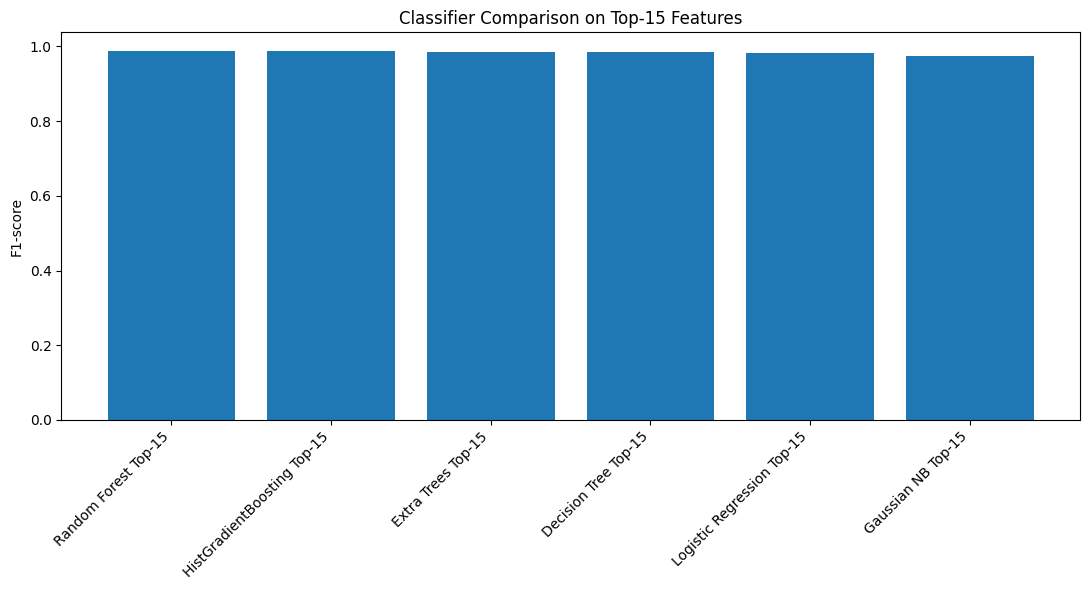

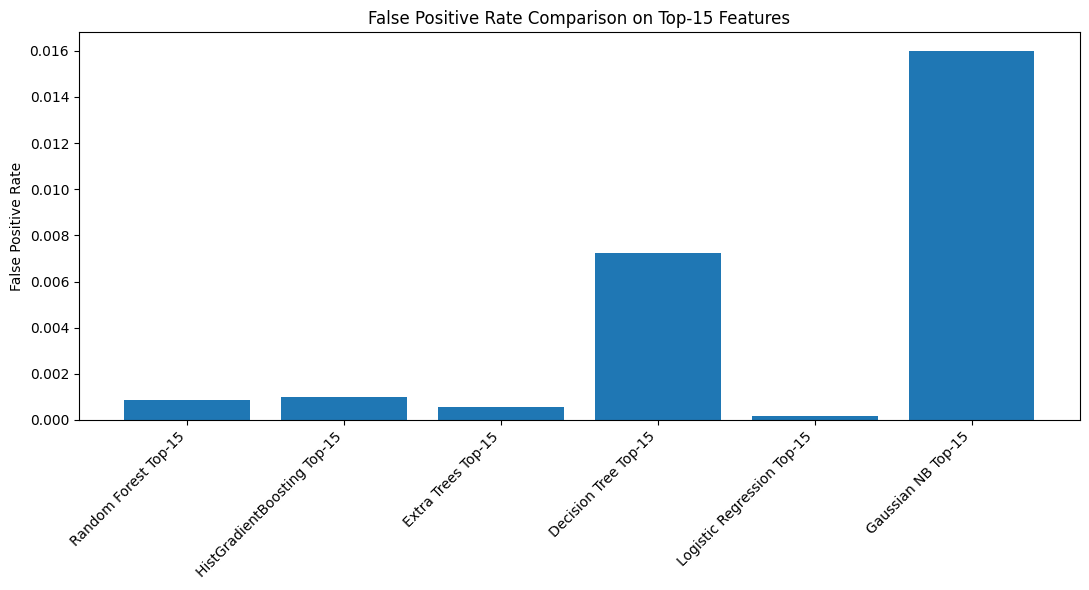

Saved figures:
- outputs/classifier_comparison_f1_top15.png
- outputs/classifier_comparison_fpr_top15.png


In [42]:

# ============================================================
# 6. Plot comparison figures
# ============================================================

import matplotlib.pyplot as plt

plot_df = comparison_df.copy()

plt.figure(figsize=(11, 6))
plt.bar(plot_df["Model"], plot_df["F1_Attack"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("F1-score")
plt.title("Classifier Comparison on Top-15 Features")
plt.tight_layout()
plt.savefig("outputs/classifier_comparison_f1_top15.png", dpi=300)
plt.show()

plt.figure(figsize=(11, 6))
plt.bar(plot_df["Model"], plot_df["FPR"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("False Positive Rate")
plt.title("False Positive Rate Comparison on Top-15 Features")
plt.tight_layout()
plt.savefig("outputs/classifier_comparison_fpr_top15.png", dpi=300)
plt.show()

print("Saved figures:")
print("- outputs/classifier_comparison_f1_top15.png")
print("- outputs/classifier_comparison_fpr_top15.png")


In [43]:

# ============================================================
# 7. Generate paper-ready table with percentages
# ============================================================

paper_table = full_plus_top15_df.copy()

paper_table["Accuracy (%)"] = paper_table["Accuracy"] * 100
paper_table["Precision (%)"] = paper_table["Precision_Attack"] * 100
paper_table["Recall (%)"] = paper_table["Recall_Attack"] * 100
paper_table["F1-score (%)"] = paper_table["F1_Attack"] * 100
paper_table["FPR (%)"] = paper_table["FPR"] * 100
paper_table["FNR (%)"] = paper_table["FNR"] * 100

paper_table = paper_table[[
    "Model",
    "Features",
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)",
    "Balanced_Accuracy",
    "MCC",
    "FPR (%)",
    "FNR (%)",
    "Training_Time_sec",
    "Inference_Time_sec",
    "Model_Size_MB"
]]

paper_table.to_csv("outputs/paper_ready_classifier_comparison.csv", index=False)

display(paper_table)

print("Saved: outputs/paper_ready_classifier_comparison.csv")


,Model,Features,Accuracy (%),Precision (%),Recall (%),F1-score (%),Balanced_Accuracy,MCC,FPR (%),FNR (%),Training_Time_sec,Inference_Time_sec,Model_Size_MB
0,Random Forest Full-39,39,98.8625,99.913172,97.810,98.850400,0.988625,0.977467,0.085,2.190,9.446707,0.205038,14.447167
1,Random Forest Top-15,15,98.8500,99.913150,97.785,98.837621,0.988500,0.977222,0.085,2.215,9.212713,0.116962,15.977227
2,HistGradientBoosting Top-15,15,98.8475,99.897850,97.795,98.835241,0.988475,0.977167,0.100,2.205,7.072530,0.250198,0.373314
3,Extra Trees Top-15,15,98.6175,99.943500,97.290,98.598900,0.986175,0.972693,0.055,2.710,3.065317,0.116250,32.810723
4,Decision Tree Top-15,15,98.6050,99.265153,97.935,98.595590,0.986050,0.972187,0.725,2.065,1.566440,0.008527,0.144036
5,Logistic Regression Top-15,15,98.1750,99.984437,96.365,98.141359,0.981750,0.964132,0.015,3.635,69.969428,0.002993,0.001327
6,Gaussian NB Top-15,15,97.5575,98.372578,96.715,97.536747,0.975575,0.951285,1.600,3.285,0.076020,0.012335,0.001578


Saved: outputs/paper_ready_classifier_comparison.csv


In [44]:

# ============================================================
# 8. Export LaTeX table for paper
# ============================================================

latex_ready = paper_table.copy()

# Round values for paper
for col in latex_ready.columns:
    if col != "Model":
        latex_ready[col] = pd.to_numeric(latex_ready[col], errors="ignore")

rounded = latex_ready.round({
    "Accuracy (%)": 2,
    "Precision (%)": 2,
    "Recall (%)": 2,
    "F1-score (%)": 2,
    "Balanced_Accuracy": 4,
    "MCC": 4,
    "FPR (%)": 4,
    "FNR (%)": 4,
    "Training_Time_sec": 3,
    "Inference_Time_sec": 4,
    "Model_Size_MB": 2
})

latex_table = rounded.to_latex(
    index=False,
    escape=True,
    caption="Comparative Performance of Machine Learning Classifiers on CICIoT2023",
    label="tab:classifier_comparison"
)

with open("outputs/classifier_comparison_table.tex", "w", encoding="utf-8") as f:
    f.write(latex_table)

print(latex_table)
print("\nSaved: outputs/classifier_comparison_table.tex")


\begin{table}
\caption{Comparative Performance of Machine Learning Classifiers on CICIoT2023}
\label{tab:classifier_comparison}
\begin{tabular}{lrrrrrrrrrrrr}
\toprule
Model & Features & Accuracy (\%) & Precision (\%) & Recall (\%) & F1-score (\%) & Balanced\_Accuracy & MCC & FPR (\%) & FNR (\%) & Training\_Time\_sec & Inference\_Time\_sec & Model\_Size\_MB \\
\midrule
Random Forest Full-39 & 39 & 98.860000 & 99.910000 & 97.810000 & 98.850000 & 0.988600 & 0.977500 & 0.085000 & 2.190000 & 9.447000 & 0.205000 & 14.450000 \\
Random Forest Top-15 & 15 & 98.850000 & 99.910000 & 97.780000 & 98.840000 & 0.988500 & 0.977200 & 0.085000 & 2.215000 & 9.213000 & 0.117000 & 15.980000 \\
HistGradientBoosting Top-15 & 15 & 98.850000 & 99.900000 & 97.800000 & 98.840000 & 0.988500 & 0.977200 & 0.100000 & 2.205000 & 7.073000 & 0.250200 & 0.370000 \\
Extra Trees Top-15 & 15 & 98.620000 & 99.940000 & 97.290000 & 98.600000 & 0.986200 & 0.972700 & 0.055000 & 2.710000 & 3.065000 & 0.116200 & 32.810000 \\
Dec

C:\Users\Hp\AppData\Local\Temp\ipykernel_21636\1983140205.py:10: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  latex_ready[col] = pd.to_numeric(latex_ready[col], errors="ignore")
